# 10 Augmentation strength and mixup: does stronger regularisation help?

Across both ST-GCN and LSTM, the advanced augmentation bundle has consistently stabilised MCA and macro F1
across seeds but left top 1 essentially unchanged, and the train to test gap stays large (23 to 27 points)
regardless. Two explanations are worth testing directly rather than assuming: the augmentations may simply
be too subtle to act as a strong regulariser, or top 1 may be limited by something augmentation cannot
reach (pipeline or sampler effects, already investigated in notebooks 03 and 08).

**Question.** Does a stronger version of the same augmentation bundle, or mixup, move validation top 1 on
ST-GCN, without costing MCA.

**Protocol.** Validation only, as in every recipe notebook. Tuning seeds (33, 44) are new, distinct from
both the stage 1/2 recipe tuning seeds (11, 22) and the reporting seeds (42, 123, 7), so this round cannot
be accused of reusing seeds it was already tuned against. Starts from the final ST-GCN recipe
(`configs/stgcn_recipe.json`); only the augmentation changes.

**Factors.**

| factor | change |
|---|---|
| strength 1.5x | the same 4 techniques, each at 1.5x its normal magnitude (rotation angle, noise std, mask span, warp amount) |
| strength 2.0x | the same 4 techniques at 2x magnitude |
| mixup 0.4 | mixup alpha 0.4 added on top of the normal strength bundle (alpha 0.2 came closest to helping in the last recipe round without quite clearing the bar) |
| strength 1.5x + mixup 0.2 | stronger geometric augmentation combined with the previous round's best mixup setting |

**Selection rule, fixed before running.** A factor helps if mean validation top 1 is at least 0.5 points
above the current recipe and MCA does not drop by more than 1 point. If something wins, it is carried into
notebooks 06 (ST-GCN final) and 09 (LSTM final) as a re-run; if nothing wins, both of those results stand
as already reported, and that is itself the useful conclusion: augmentation strength was not the limiting
factor on top 1.

Logs to `BadmintonPoseAnalysis/experiments/augmentation_strength`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/augmentation_strength"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs") + "/experiments/augmentation_strength"
os.makedirs(OUT, exist_ok=True)

SEEDS = [33, 44]
SPLITS = ("train", "val")
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)

BASELINE = {"policy": "advanced", "mixup_alpha": 0.0}
FACTORS = {
    "strength_1.5x": {"policy": "advanced_1.5x", "mixup_alpha": 0.0},
    "strength_2.0x": {"policy": "advanced_2.0x", "mixup_alpha": 0.0},
    "mixup_0.4": {"policy": "advanced", "mixup_alpha": 0.4},
    "strength_1.5x_mixup_0.2": {"policy": "advanced_1.5x", "mixup_alpha": 0.2},
}
# register the scaled policies at runtime (see dataset.scaled_advanced_augmentations)
ds.AUGMENTATION_POLICIES["advanced_1.5x"] = ds.scaled_advanced_augmentations(1.5)
ds.AUGMENTATION_POLICIES["advanced_2.0x"] = ds.scaled_advanced_augmentations(2.0)

MIN_GAIN, MAX_MCA_DROP, TIE = 0.005, 0.01, 0.003
print("recipe:", RECIPE)

recipe: {'model': 'ST-GCN', 'normalisation': 'body_court', 'selected': 'combination', 'changes_from_baseline': {'weight_decay': 0.005, 'target_per_class': 300}, 'augmentation': 'advanced', 'min_native_frames': 5, 'batch_size': 16, 'lr': 0.01, 'momentum': 0.9, 'gamma': 0.1, 'select_metric': 'top1', 'weight_decay': 0.005, 'label_smoothing': 0.0, 'schedule': 'step10', 'target_per_class': 300, 'num_epochs': 60, 'patience': 20, 'tuning': {'seeds': [11, 22], 'val_top1': 0.7612, 'baseline_val_top1': 0.7394}}


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
forward = stgcn_model.make_forward(USE_COURT)
in_channels = 7 if USE_COURT else 5

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## Smoke test

Confirms the scaled policies actually produce larger perturbations than the default bundle, and that
mixup still works alongside a scaled policy.

In [4]:
rng = np.random.RandomState(0)
sample_row = manifest[manifest["split"] == "train"].sample(1, random_state=0).iloc[0]
stem = os.path.splitext(os.path.basename(sample_row["filepath"]))[0]
clip = np.load(f"{KEYPOINTS}/{sample_row['class_name']}/{stem}.npy").astype(np.float32)

for name in ["advanced", "advanced_1.5x", "advanced_2.0x"]:
    shifts = []
    for _ in range(100):
        out = clip.copy()
        for fn in ds.AUGMENTATION_POLICIES[name]:
            out = fn(out)
        shifts.append(np.abs(out[..., :2] - clip[..., :2]).mean() / ds.body_height(clip))
    print(f"{name:16s} mean shift (body heights): {np.mean(shifts):.4f}")

tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, "advanced_1.5x", NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=300, num_workers=2, eval_workers=2)
model = stgcn_model.build_stgcn(in_channels, len(class_names)).to(device)
batch = next(iter(loaders["train"]))
mixed = ds.mixup_batch(batch, alpha=0.2, num_classes=len(class_names))
logits = forward(model, mixed, device)
loss = -(mixed["soft_label"].to(device) * torch.log_softmax(logits, dim=1)).sum(1).mean()
assert torch.isfinite(loss)
loss.backward()
assert not [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
del model, loaders
print("smoke test passed")

advanced         mean shift (body heights): 0.0087
advanced_1.5x    mean shift (body heights): 0.0132
advanced_2.0x    mean shift (body heights): 0.0147
smoke test passed


## Run function and stage A

In [5]:
results_path = f"{OUT}/results.csv"


def load_results():
    return pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["config", "seed"])


def run_config(name, overrides, seed):
    done = load_results()
    if ((done["config"] == name) & (done["seed"] == seed)).any():
        print(f"skip {name} seed {seed}, already done")
        return
    cfg = {**BASELINE, **overrides}
    run_name = f"stgcn_aug_{name}_s{seed}"
    print(f"\n=== {run_name}  {overrides or 'baseline'} ===")
    tr.seed_everything(seed)

    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["aug_strength", name, "stgcn", f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, **cfg, "config": name, "changes": overrides, "seed": seed,
                  "keypoints": KEYPOINTS, "split_sha256": split_hash, "evaluated_splits": list(SPLITS)})

    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, cfg["policy"], NORMALISATION, seed=seed,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
    model = stgcn_model.build_stgcn(in_channels, len(class_names)).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                            splits=SPLITS, mixup_alpha=cfg["mixup_alpha"], num_classes=len(class_names))
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"config": name, "seed": seed})
    task.close()

    pd.concat([done, pd.DataFrame([metrics])], ignore_index=True).to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()


configs_a = {"baseline": {}, **FACTORS}
for name, overrides in configs_a.items():
    for seed in SEEDS:
        run_config(name, overrides, seed)

skip baseline seed 33, already done
skip baseline seed 44, already done
skip strength_1.5x seed 33, already done
skip strength_1.5x seed 44, already done
skip strength_2.0x seed 33, already done
skip strength_2.0x seed 44, already done
skip mixup_0.4 seed 33, already done
skip mixup_0.4 seed 44, already done
skip strength_1.5x_mixup_0.2 seed 33, already done
skip strength_1.5x_mixup_0.2 seed 44, already done


## Selection

In [6]:
def summarise(results):
    g = results.groupby("config")
    out = pd.DataFrame({
        "val top1": g["val_top1"].mean(), "val top1 std": g["val_top1"].std().fillna(0),
        "val mca": g["val_mca"].mean(), "val macro f1": g["val_macro_f1"].mean(),
        "train val gap": g["train_val_gap"].mean(), "best epoch": g["best_epoch"].mean(), "seeds": g["seed"].count(),
    })
    return out


results = load_results()
table = summarise(results)
base = table.loc["baseline"]
table["d top1"] = table["val top1"] - base["val top1"]
table["d mca"] = table["val mca"] - base["val mca"]
table["helps"] = [(n != "baseline") and (r["d top1"] >= MIN_GAIN) and (r["d mca"] >= -MAX_MCA_DROP)
                  for n, r in table.iterrows()]
helpful = [n for n in FACTORS if table.loc[n, "helps"]]

best_top1 = table.loc[["baseline"] + helpful, "val top1"].max() if helpful else base["val top1"]
eligible = ["baseline"] + helpful
close = [n for n in eligible if best_top1 - table.loc[n, "val top1"] <= TIE]
selected = min(close, key=lambda n: (0 if n == "baseline" else 1, -table.loc[n, "val top1"]))
print("factors that help:", helpful or "none")
print("selected:", selected)

task = Task.init(project_name=PROJECT, task_name="augmentation_strength_selection", task_type=Task.TaskTypes.qc,
                 tags=["aug_strength", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task.get_logger()
task.connect({"recipe": RECIPE, "factors": FACTORS, "seeds": SEEDS,
              "rule": {"min_gain": MIN_GAIN, "max_mca_drop": MAX_MCA_DROP, "tie": TIE}, "selected": selected})

show = table.assign(**{c: (100 * table[c]).round(2) for c in ["val top1", "val top1 std", "val mca",
                                                                "val macro f1", "train val gap", "d top1", "d mca"]})
show["selected"] = [n == selected for n in show.index]
slog.report_table("augmentation strength comparison (validation)", "val", iteration=0,
                  table_plot=show.round({"best epoch": 1}).reset_index())
task.upload_artifact("results", artifact_object=results_path)

selected_policy = (BASELINE if selected == "baseline" else {**BASELINE, **FACTORS[selected]})
with open(f"{REPO}/configs/stgcn_augmentation.json", "w") as f:
    json.dump({"selected": selected, **selected_policy,
               "tuning": {"seeds": SEEDS, "val_top1": float(table.loc[selected, "val top1"]),
                          "baseline_val_top1": float(base["val top1"])}}, f, indent=2)
task.upload_artifact("selected_augmentation", artifact_object=f"{REPO}/configs/stgcn_augmentation.json")

factors that help: none
selected: baseline
ClearML Task: created new task id=b2d3ce799fed47e291dafd14976825cb
2026-10-01 06:28:33,929 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/a7099dbd7e3e4837a92bdfb10e064af4/tasks/b2d3ce799fed47e291dafd14976825cb/output/log


True

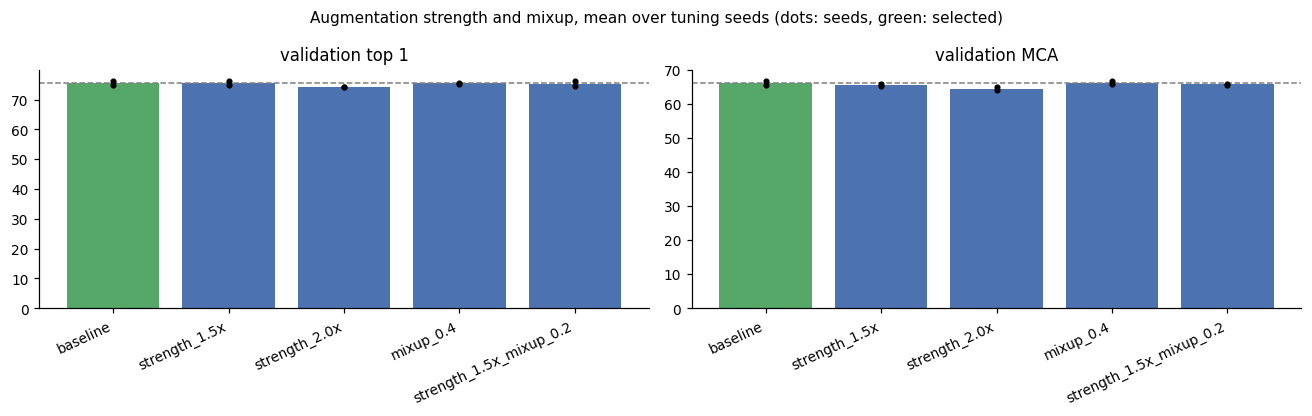

In [7]:
order = ["baseline", *FACTORS]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(order))
for ax, metric, title in zip(axes, ["val_top1", "val_mca"], ["validation top 1", "validation MCA"]):
    means = [results.loc[results["config"] == n, metric].mean() for n in order]
    colours = ["#55a868" if n == selected else "#b0b0b0" if n == "baseline" else "#4c72b0" for n in order]
    ax.bar(x, 100 * np.array(means), color=colours)
    for i, n in enumerate(order):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["config"] == n, metric], color="black", s=9, zorder=3)
    ax.axhline(100 * results.loc[results["config"] == "baseline", metric].mean(), color="grey", ls="--", lw=1)
    ax.set_xticks(x, order, rotation=25, ha="right")
    ax.set_title(title)
fig.suptitle("Augmentation strength and mixup, mean over tuning seeds (dots: seeds, green: selected)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("augmentation strength comparison", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()
task.close()

## Next step

- If `selected` is anything other than `"baseline"`, `configs/stgcn_augmentation.json` records the winning
  policy and mixup setting. Re-run notebook 06 (ST-GCN final) and notebook 09 (LSTM final) substituting this
  policy for `"advanced"` everywhere, on the same 3 reporting seeds, to get updated headline numbers.
- If `selected` is `"baseline"`, nothing changes: the existing ST-GCN and LSTM final results stand, and the
  conclusion for the thesis is that augmentation strength was tested directly and found not to be the
  limiting factor on top 1, which is itself worth a sentence in the discussion rather than leaving the
  question open.